In [1]:
import pandas as pd

df = pd.read_csv("Admission_Predict.csv")

print(df.columns)

Index(['Serial No.', 'GRE Score', 'TOEFL Score', 'University Rating', 'SOP',
       'LOR ', 'CGPA', 'Research', 'Chance of Admit '],
      dtype='str')


Decision Tree confusion matrix:
[[ 0  7]
 [ 3 70]]

Naive Bayes confusion matrix:
[[ 6  1]
 [13 60]]

Performance comparison:
        Model  Accuracy  Precision  Recall  F1-score
Decision Tree     0.875      0.909   0.959     0.933
  Naive Bayes     0.825      0.984   0.822     0.896

Most suitable model based on F1-score: Decision Tree


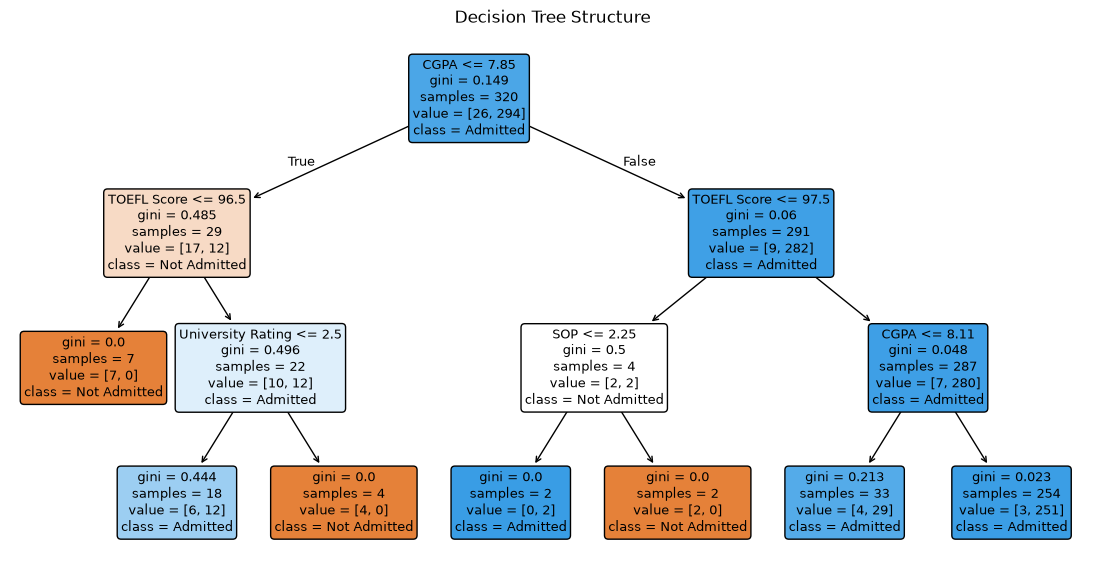

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix
)

# Load dataset
df = pd.read_csv("Admission_Predict.csv")
df = df.drop(columns=["Serial No."], errors="ignore")

# Convert admission chance into classes: 1 = Admitted, 0 = Not Admitted
df["Admitted"] = (df["Chance of Admit "] >= 0.5).astype(int)

# Separate features and target
X = df.drop(columns=["Chance of Admit ", "Admitted"])
y = df["Admitted"]

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Create and train the models
tree_model = DecisionTreeClassifier(random_state=42, max_depth=3)
nb_model = GaussianNB()

tree_model.fit(X_train, y_train)
nb_model.fit(X_train, y_train)

# Make predictions
pred_tree = tree_model.predict(X_test)
pred_nb = nb_model.predict(X_test)

# Display confusion matrices
print("Decision Tree confusion matrix:")
print(confusion_matrix(y_test, pred_tree))
print()

print("Naive Bayes confusion matrix:")
print(confusion_matrix(y_test, pred_nb))
print()

# Compare performance using standard metrics
results = pd.DataFrame({
    "Model": ["Decision Tree", "Naive Bayes"],
    "Accuracy": [
        accuracy_score(y_test, pred_tree),
        accuracy_score(y_test, pred_nb)
    ],
    "Precision": [
        precision_score(y_test, pred_tree, zero_division=0),
        precision_score(y_test, pred_nb, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, pred_tree, zero_division=0),
        recall_score(y_test, pred_nb, zero_division=0)
    ],
    "F1-score": [
        f1_score(y_test, pred_tree, zero_division=0),
        f1_score(y_test, pred_nb, zero_division=0)
    ]
})

print("Performance comparison:")
print(results.round(3).to_string(index=False))

# Identify the model with the higher F1-score
best_model = results.loc[results["F1-score"].idxmax(), "Model"]
print("\nMost suitable model based on F1-score:", best_model)

# Display the Decision Tree structure
plt.figure(figsize=(14, 7))
plot_tree(
    tree_model,
    feature_names=X.columns,
    class_names=["Not Admitted", "Admitted"],
    filled=True,
    rounded=True,
    max_depth=3
)
plt.title("Decision Tree Structure")
plt.show()